# 딥러닝 기초 1일차 실습과제: 퍼셉트론과 활성화 함수

## 과제 개요
이 과제에서는 신경망의 기본 단위인 **퍼셉트론**을 구현하고, 다양한 **활성화 함수**의 특성을 비교합니다.

### 학습 목표
1. 퍼셉트론의 구조와 원리 이해
2. 논리 게이트(AND, OR, NAND, XOR) 구현
3. 다층 퍼셉트론의 필요성 이해
4. 활성화 함수(Sigmoid, ReLU, Tanh) 비교

### 예상 소요 시간
약 **1시간**

### 제출물
- 완성된 노트북 파일 (.ipynb)
- 모든 과제 답변 작성 완료

---

> 📝 **작성자**: 조태희 · OZ 코딩 스쿨 AI 헬스케어 부트캠프 6기
> ▶️ **실행 방법**: Colab에서 `런타임 → 모두 실행`을 누르면 위에서부터 차례로 실행됩니다. 이 노트북은 `numpy`, `matplotlib`만 사용하므로 별도 설치가 필요 없어요.

## Part 0: 환경 설정

In [1]:
# 필요한 라이브러리 import
import numpy as np               # 배열·수학 계산을 빠르게 해 주는 라이브러리 (np라는 별명으로 사용)
import matplotlib.pyplot as plt  # 그래프를 그리는 라이브러리 (plt라는 별명으로 사용)

# 재현성을 위한 시드 설정
np.random.seed(42)  # 난수의 '출발점'을 고정 → 언제 실행해도 같은 난수가 나와서 결과를 똑같이 재현할 수 있음

print("환경 설정 완료!")  # 여기까지 오류 없이 실행됐는지 확인하는 메시지

환경 설정 완료!


---

## Part 1: 퍼셉트론 기초

### 퍼셉트론이란?
- 입력값에 가중치를 곱하고 편향을 더한 후, 활성화 함수를 적용하는 가장 단순한 신경망 단위
- 수식: $y = f(w_1 x_1 + w_2 x_2 + b)$

### 논리 게이트 진리표
| $x_1$ | $x_2$ | AND | OR | NAND | XOR |
|:-----:|:-----:|:---:|:--:|:----:|:---:|
| 0 | 0 | 0 | 0 | 1 | 0 |
| 0 | 1 | 0 | 1 | 1 | 1 |
| 1 | 0 | 0 | 1 | 1 | 1 |
| 1 | 1 | 1 | 1 | 0 | 0 |

In [2]:
# ============================================
# 퍼셉트론 기본 구현
# ============================================

def step_function(x):
    """계단 함수: 0보다 크면 1, 아니면 0"""
    return 1 if x > 0 else 0  # 가중합이 0을 '넘으면' 신호를 보냄(1), 아니면 조용히(0)

def perceptron(x1, x2, w1, w2, b):
    """
    퍼셉트론 연산
    - x1, x2: 입력값
    - w1, w2: 가중치 (입력의 중요도)
    - b: 편향 (발화 임계값 조절)
    """
    z = w1 * x1 + w2 * x2 + b  # 가중합 계산: 각 입력 × 중요도를 모두 더하고 편향(기본 점수)을 더함
    return step_function(z)     # 활성화 함수 적용: 가중합을 0/1 출력으로 바꿈

# AND 게이트: 둘 다 1일 때만 1
def and_gate(x1, x2):
    w1, w2, b = 0.5, 0.5, -0.7           # 두 입력이 모두 1이어야 0.5+0.5-0.7=0.3 > 0 이 됨
    return perceptron(x1, x2, w1, w2, b)  # 정해진 가중치·편향으로 퍼셉트론 계산

# OR 게이트: 하나라도 1이면 1
def or_gate(x1, x2):
    w1, w2, b = 0.5, 0.5, -0.3           # 입력 하나만 1이어도 0.5-0.3=0.2 > 0 이 됨
    return perceptron(x1, x2, w1, w2, b)  # 정해진 가중치·편향으로 퍼셉트론 계산

# 테스트
print("AND 게이트 테스트:")                   # 제목 출력
for x1, x2 in [(0,0), (0,1), (1,0), (1,1)]:  # 진리표의 4가지 입력 조합을 하나씩 꺼냄
    print(f"  AND({x1}, {x2}) = {and_gate(x1, x2)}")  # 각 조합의 AND 결과 출력

print("\nOR 게이트 테스트:")                  # 한 줄 띄우고 제목 출력
for x1, x2 in [(0,0), (0,1), (1,0), (1,1)]:  # 4가지 입력 조합 반복
    print(f"  OR({x1}, {x2}) = {or_gate(x1, x2)}")    # 각 조합의 OR 결과 출력

AND 게이트 테스트:
  AND(0, 0) = 0
  AND(0, 1) = 0
  AND(1, 0) = 0
  AND(1, 1) = 1

OR 게이트 테스트:
  OR(0, 0) = 0
  OR(0, 1) = 1
  OR(1, 0) = 1
  OR(1, 1) = 1


### [필수] 과제 1-1: NAND 게이트 구현하기

NAND 게이트는 AND 게이트의 반대입니다. 위의 진리표를 참고하여 NAND 게이트를 구현하세요.

**힌트**: AND 게이트의 출력을 뒤집으면 NAND가 됩니다. 가중치나 편향의 부호를 바꿔보세요!

In [3]:
# [과제 1-1] NAND 게이트 구현
# AND의 가중치·편향 부호를 모두 뒤집으면 가중합 z의 부호도 뒤집혀서 출력이 정확히 반대가 됨

def nand_gate(x1, x2):
    w1 = -0.5  # 가중치 1: 입력이 1이면 점수를 깎음 (AND의 +0.5를 뒤집음)
    w2 = -0.5  # 가중치 2: 마찬가지로 점수를 깎음
    b = 0.7    # 편향: 기본 점수를 +0.7로 시작 (AND의 -0.7을 뒤집음) → 둘 다 1일 때만 0.7-1.0=-0.3 ≤ 0

    return perceptron(x1, x2, w1, w2, b)  # 위 가중치·편향으로 퍼셉트론 계산

# 테스트 - 결과가 NAND 진리표와 일치하는지 확인
print("NAND 게이트 테스트:")                                          # 제목 출력
print("기대값: NAND(0,0)=1, NAND(0,1)=1, NAND(1,0)=1, NAND(1,1)=0")  # 진리표의 정답
print()                                                              # 빈 줄
for x1, x2 in [(0,0), (0,1), (1,0), (1,1)]:  # 4가지 입력 조합 반복
    result = nand_gate(x1, x2)               # NAND 계산
    print(f"  NAND({x1}, {x2}) = {result}")  # 결과 출력

# 자동 채점: 진리표와 하나라도 다르면 AssertionError가 나서 바로 알 수 있음
nand_truth = {(0,0): 1, (0,1): 1, (1,0): 1, (1,1): 0}                  # NAND 정답표
assert all(nand_gate(*k) == v for k, v in nand_truth.items()), "NAND 진리표와 다릅니다!"  # 전부 맞는지 검사
print("\n✅ 4가지 입력 모두 NAND 진리표와 일치합니다.")                  # 통과 메시지

NAND 게이트 테스트:
기대값: NAND(0,0)=1, NAND(0,1)=1, NAND(1,0)=1, NAND(1,1)=0

  NAND(0, 0) = 1
  NAND(0, 1) = 1
  NAND(1, 0) = 1
  NAND(1, 1) = 0

✅ 4가지 입력 모두 NAND 진리표와 일치합니다.


💡 **왜 이 값일까요?**
가중합을 직접 계산해 보면 `z = -0.5·x₁ - 0.5·x₂ + 0.7` 이므로 (0,0)→0.7, (0,1)→0.2, (1,0)→0.2, (1,1)→-0.3 이 됩니다. **둘 다 1일 때만** z가 0 이하로 떨어져 출력이 0이 되죠.
AND의 `(0.5, 0.5, -0.7)`에 -1을 곱하면 z의 부호가 정확히 반대가 되므로, "출력 뒤집기 = 가중치·편향 부호 뒤집기"라는 힌트가 그대로 적용된 것입니다. (가중치는 꼭 이 값이 아니어도 돼요. 예를 들어 `(-1, -1, 1.5)`도 NAND가 됩니다.)

---

## Part 2: XOR 문제와 다층 퍼셉트론

XOR 게이트는 단일 퍼셉트론으로 구현할 수 없습니다. 왜일까요?

- XOR: 입력이 서로 다를 때 1, 같을 때 0
- 단일 퍼셉트론은 **하나의 직선**으로만 분류 가능 (선형 분리)
- XOR은 직선 하나로 분류할 수 없음 -> **다층 퍼셉트론(MLP)** 필요!

In [4]:
# XOR 게이트 구현 (다층 퍼셉트론 개념)
# XOR = AND(NAND(x1, x2), OR(x1, x2))

def nand_gate_solution(x1, x2):
    """NAND 게이트 정답"""
    w1, w2, b = -0.5, -0.5, 0.7           # 과제 1-1에서 구한 것과 같은 값
    return perceptron(x1, x2, w1, w2, b)  # 퍼셉트론 계산

def xor_gate(x1, x2):
    """
    XOR 게이트 - 2층 퍼셉트론으로 구현

    구조:
    입력층: x1, x2
    은닉층: NAND(x1,x2), OR(x1,x2)  <- 2개의 퍼셉트론
    출력층: AND(은닉1, 은닉2)       <- 1개의 퍼셉트론
    """
    # 은닉층 (첫 번째 층)
    s1 = nand_gate_solution(x1, x2)  # 첫 번째 뉴런: "둘 다 1은 아니다"를 판단
    s2 = or_gate(x1, x2)             # 두 번째 뉴런: "하나 이상 1이다"를 판단

    # 출력층 (두 번째 층)
    y = and_gate(s1, s2)             # 두 조건을 동시에 만족 = "정확히 하나만 1" = XOR

    return y                         # 최종 출력

# 테스트
print("XOR 게이트 테스트 (다층 퍼셉트론):")                       # 제목
print("기대값: XOR(0,0)=0, XOR(0,1)=1, XOR(1,0)=1, XOR(1,1)=0")  # 정답
print()                                                          # 빈 줄
for x1, x2 in [(0,0), (0,1), (1,0), (1,1)]:  # 4가지 입력 조합 반복
    result = xor_gate(x1, x2)                # 2층 퍼셉트론으로 XOR 계산
    print(f"  XOR({x1}, {x2}) = {result}")   # 결과 출력

print("\n=> 여러 퍼셉트론을 쌓으면 비선형 문제도 해결할 수 있습니다!")  # 핵심 메시지
print("   이것이 바로 '다층 퍼셉트론(MLP)'의 핵심 아이디어입니다.")

XOR 게이트 테스트 (다층 퍼셉트론):
기대값: XOR(0,0)=0, XOR(0,1)=1, XOR(1,0)=1, XOR(1,1)=0

  XOR(0, 0) = 0
  XOR(0, 1) = 1
  XOR(1, 0) = 1
  XOR(1, 1) = 0

=> 여러 퍼셉트론을 쌓으면 비선형 문제도 해결할 수 있습니다!
   이것이 바로 '다층 퍼셉트론(MLP)'의 핵심 아이디어입니다.


### 🔍 직접 확인해 보기: 단일 퍼셉트론으로 XOR이 정말 안 될까?

말로만 듣기보다 **직접 실험**해 보겠습니다. 가중치 `w1, w2`와 편향 `b`를 -1.0 ~ 1.0 사이에서 0.1 간격으로 바꿔 가며 (21 × 21 × 21 = 9,261가지 조합) 각 게이트의 진리표를 완벽히 맞히는 조합이 몇 개인지 세어 봅니다. 그리고 각 퍼셉트론이 긋는 **결정 경계(직선)**도 그림으로 확인합니다.

시험한 조합 수: 9,261개
  AND  진리표를 완벽히 맞히는 단일 퍼셉트론 조합: 224개
  OR   진리표를 완벽히 맞히는 단일 퍼셉트론 조합: 385개
  NAND 진리표를 완벽히 맞히는 단일 퍼셉트론 조합: 159개
  XOR  진리표를 완벽히 맞히는 단일 퍼셉트론 조합: 0개


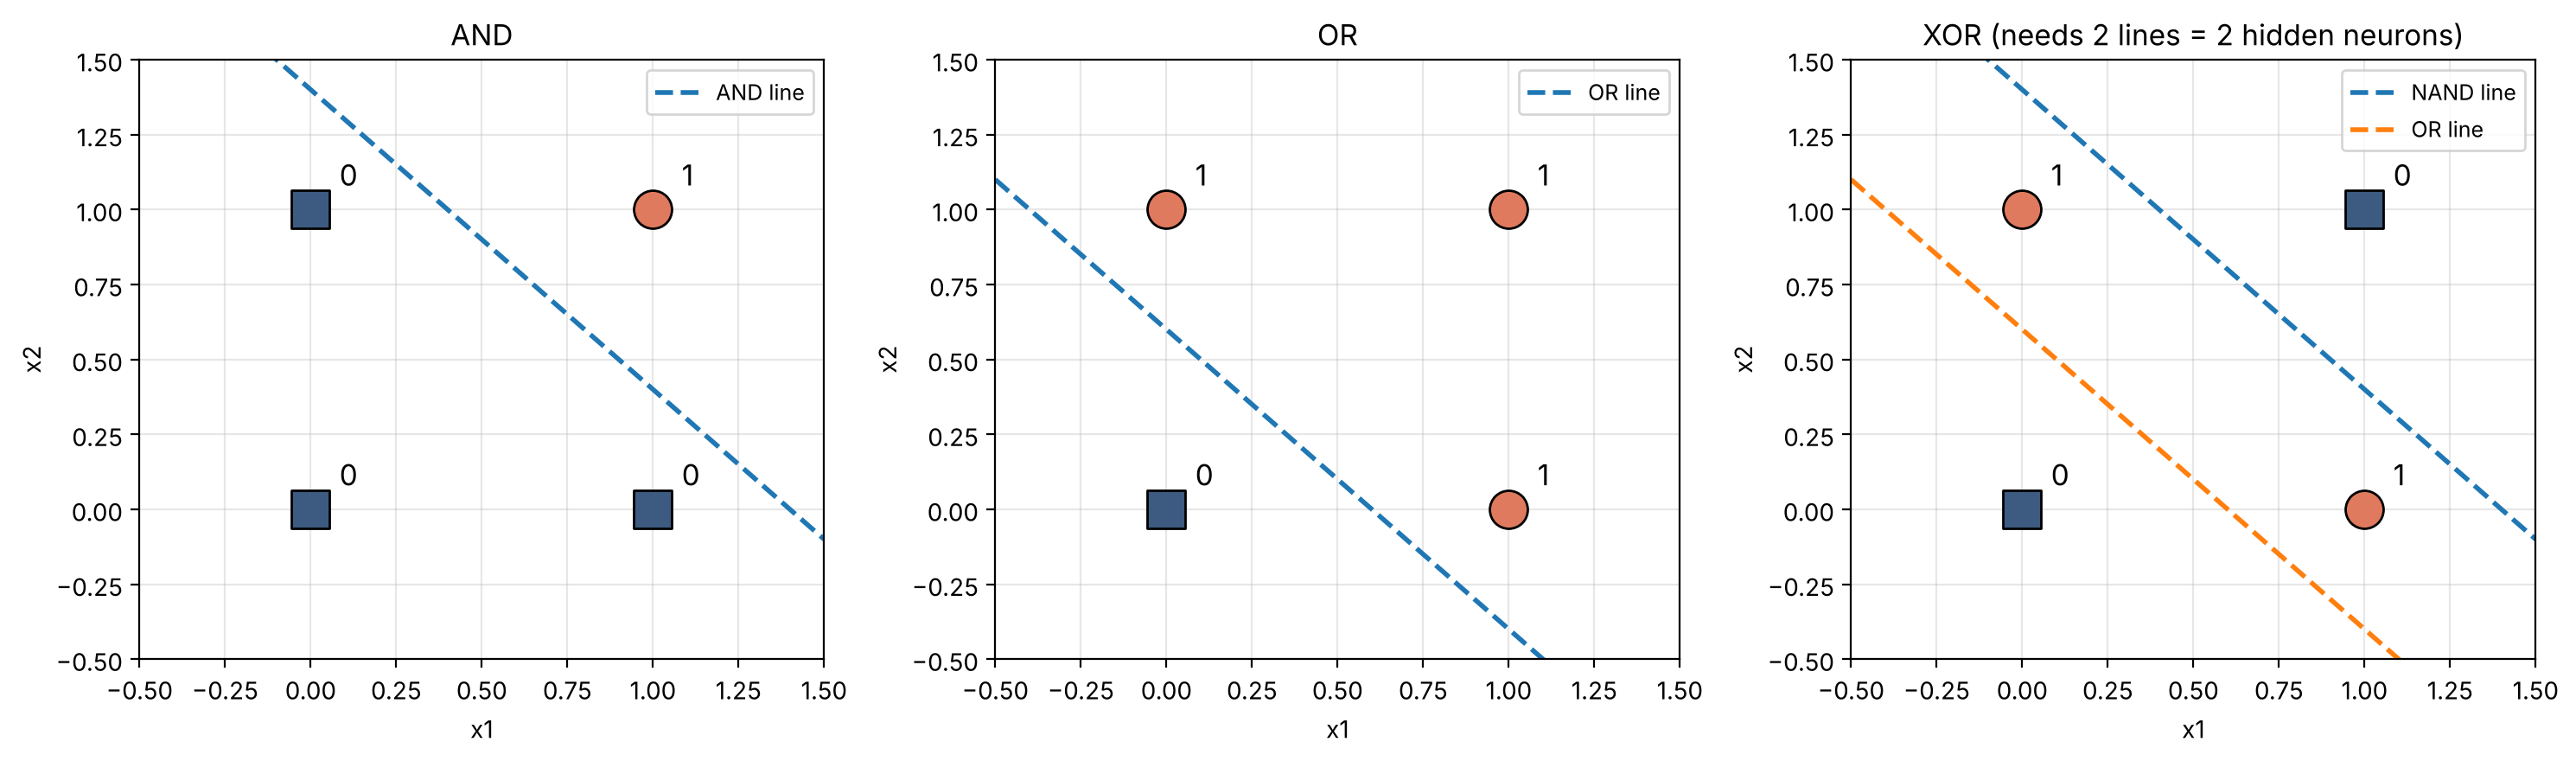

In [5]:
# 1) 9,261가지 (w1, w2, b) 조합을 모두 시험해 보기
grid = np.round(np.arange(-1.0, 1.01, 0.1), 1)   # -1.0, -0.9, ..., 1.0 (21개) / round로 소수점 오차 정리
inputs = [(0,0), (0,1), (1,0), (1,1)]             # 진리표의 4가지 입력
truth = {                                         # 각 게이트의 정답 출력 (입력 순서는 위 inputs와 같음)
    'AND':  [0, 0, 0, 1],
    'OR':   [0, 1, 1, 1],
    'NAND': [1, 1, 1, 0],
    'XOR':  [0, 1, 1, 0],
}

counts = {name: 0 for name in truth}              # 게이트별로 '정답 조합 개수'를 셀 상자
for w1 in grid:                                   # 가중치 1 후보를 하나씩
    for w2 in grid:                               # 가중치 2 후보를 하나씩
        for b in grid:                            # 편향 후보를 하나씩
            out = [perceptron(x1, x2, w1, w2, b) for x1, x2 in inputs]  # 이 조합의 4가지 출력
            for name, target in truth.items():    # 각 게이트의 정답과 비교
                if out == target:                 # 4개 모두 맞으면
                    counts[name] += 1             # 해당 게이트의 '성공 조합'으로 카운트

print(f"시험한 조합 수: {len(grid)**3:,}개")       # 전체 조합 수 출력
for name, c in counts.items():                    # 게이트별 결과 출력
    print(f"  {name:<4} 진리표를 완벽히 맞히는 단일 퍼셉트론 조합: {c:,}개")

# 2) 결정 경계 그림: w1*x1 + w2*x2 + b = 0 인 직선 → x2 = -(w1*x1 + b) / w2
def boundary(w1, w2, b, xs):
    return -(w1 * xs + b) / w2                    # 직선 위의 x2 좌표 계산

xs = np.linspace(-0.5, 1.5, 50)                   # 직선을 그릴 x1 범위
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5)) # 그림 3칸 (AND, OR, XOR)
panels = [
    ('AND', truth['AND'], [(0.5, 0.5, -0.7, 'AND line')]),
    ('OR',  truth['OR'],  [(0.5, 0.5, -0.3, 'OR line')]),
    ('XOR (needs 2 lines = 2 hidden neurons)', truth['XOR'],
     [(-0.5, -0.5, 0.7, 'NAND line'), (0.5, 0.5, -0.3, 'OR line')]),
]
for ax, (title, target, lines) in zip(axes, panels):  # 칸마다 하나의 게이트를 그림
    for (x1, x2), t in zip(inputs, target):            # 4개 점을 정답(0/1)에 따라 다른 모양으로 표시
        ax.scatter(x1, x2, s=250, c='#E07A5F' if t == 1 else '#3D5A80',
                   marker='o' if t == 1 else 's', edgecolors='black', zorder=3)
        ax.annotate(f'{t}', (x1, x2), textcoords='offset points', xytext=(12, 10), fontsize=12)  # 점 옆에 정답 표시
    for w1, w2, b, label in lines:                     # 퍼셉트론이 긋는 직선 그리기
        ax.plot(xs, boundary(w1, w2, b, xs), '--', linewidth=2, label=label)
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)     # 보기 좋은 범위로 고정
    ax.set_xlabel('x1'); ax.set_ylabel('x2')           # 축 이름
    ax.set_title(title)                                # 제목
    ax.legend(loc='upper right', fontsize=9)           # 범례
    ax.grid(True, alpha=0.3)                           # 옅은 격자
plt.tight_layout()                                     # 칸 간격 자동 조정
plt.show()                                             # 그림 출력

### [필수] 과제 2-1: 퍼셉트론 이해도 점검

아래 질문에 **각각 1-2문장**으로 답하세요:

1. 퍼셉트론에서 **가중치(weight)**의 역할은 무엇인가요?
   - 답변: 가중치는 **각 입력이 출력에 얼마나 큰 영향을 주는지(중요도)**를 정하는 값입니다. 가중치가 클수록 그 입력이 가중합 z를 크게 움직여 출력(0 또는 1) 결정에 더 큰 영향을 주고(음수면 반대 방향으로 작용), "학습"이란 바로 이 가중치(와 편향)를 데이터에 맞게 조정하는 과정입니다.
   - 💡 비유: 회의에서 사람마다 **발언권의 무게**가 다른 것과 같아요. 전문가(가중치 큼)의 의견은 결론을 크게 흔들고, 비전문가(가중치 작음)의 의견은 조금만 반영됩니다.

2. 단일 퍼셉트론으로 XOR을 구현할 수 없는 이유는?
   - 답변: 단일 퍼셉트론의 결정 경계는 `w₁x₁ + w₂x₂ + b = 0`이라는 **직선 하나**뿐이라 선형 분리가 가능한 문제만 풀 수 있는데, XOR은 출력이 1인 점 (0,1)·(1,0)과 0인 점 (0,0)·(1,1)이 대각선으로 엇갈려 있어 **직선 하나로는 두 그룹을 나눌 수 없기 때문**입니다. 위 실험에서도 9,261가지 조합 중 AND·OR·NAND는 정답 조합이 있었지만 XOR을 만족하는 조합은 **0개**였고, 직선 2개(NAND 뉴런 + OR 뉴런)를 겹쳐야 XOR 영역을 구분할 수 있었습니다.

---

## Part 3: 활성화 함수 비교

활성화 함수는 신경망에 **비선형성**을 부여합니다. 대표적인 활성화 함수들을 비교해봅시다.

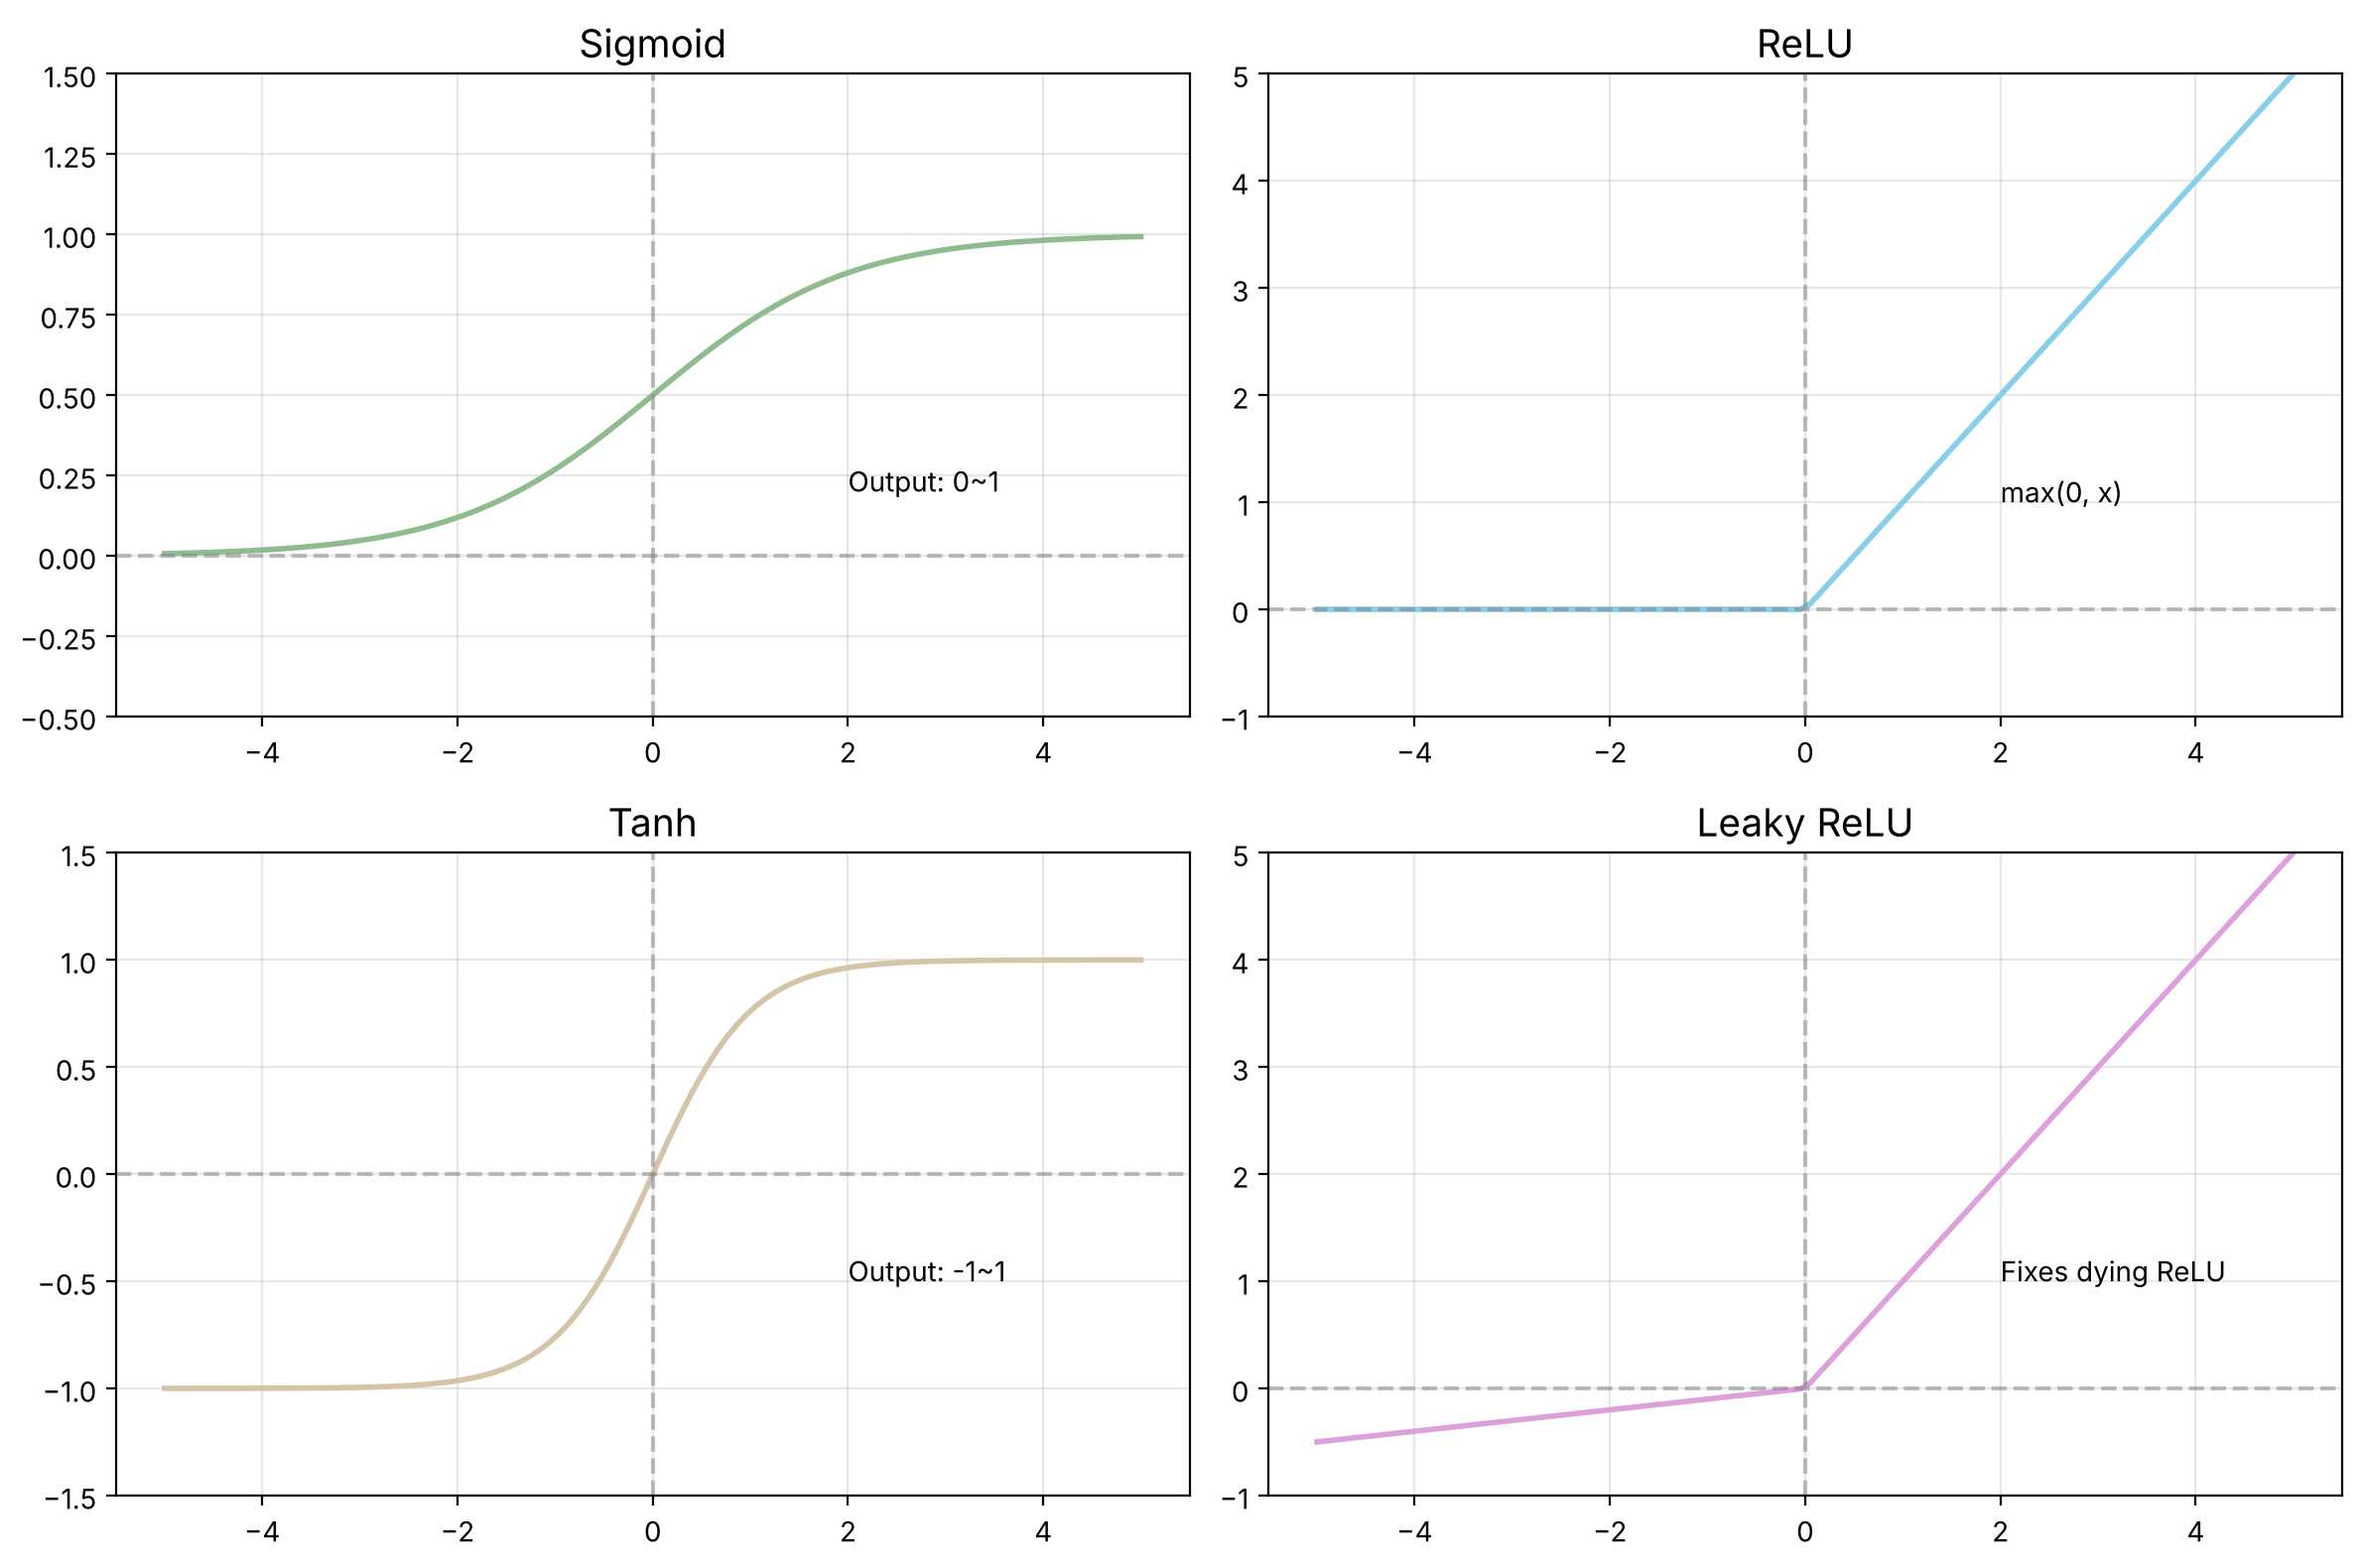

In [6]:
# ============================================
# 활성화 함수 정의
# ============================================

def sigmoid(x):
    """Sigmoid: 출력을 0~1 사이로 압축"""
    return 1 / (1 + np.exp(-x))        # 큰 양수 → 1에 가까움, 큰 음수 → 0에 가까움

def relu(x):
    """ReLU: 음수는 0, 양수는 그대로"""
    return np.maximum(0, x)            # 0과 x 중 큰 값 → 음수는 0으로 잘림

def tanh(x):
    """Tanh: 출력을 -1~1 사이로 압축"""
    return np.tanh(x)                  # sigmoid와 모양은 비슷하지만 0을 중심으로 대칭

def leaky_relu(x, alpha=0.1):
    """Leaky ReLU: 음수에도 작은 기울기 부여"""
    return np.where(x > 0, x, alpha * x)  # 양수는 그대로, 음수는 0.1배로 '살짝' 통과

# 시각화
x = np.linspace(-5, 5, 100)            # -5부터 5까지 100개의 점 (그래프의 x축)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))  # 2행 2열 = 그림 4칸 준비

# Sigmoid
axes[0, 0].plot(x, sigmoid(x), color='#8FBC8F', linewidth=2)       # 곡선 그리기
axes[0, 0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)   # y=0 기준선
axes[0, 0].axvline(x=0, color='gray', linestyle='--', alpha=0.5)   # x=0 기준선
axes[0, 0].set_title('Sigmoid', fontsize=14)                       # 제목
axes[0, 0].set_ylim(-0.5, 1.5)                                     # y축 범위
axes[0, 0].grid(True, alpha=0.3)                                   # 옅은 격자
axes[0, 0].text(2, 0.2, 'Output: 0~1', fontsize=10)                # 설명 글자

# ReLU
axes[0, 1].plot(x, relu(x), color='#87CEEB', linewidth=2)          # 곡선 그리기
axes[0, 1].axhline(y=0, color='gray', linestyle='--', alpha=0.5)   # y=0 기준선
axes[0, 1].axvline(x=0, color='gray', linestyle='--', alpha=0.5)   # x=0 기준선
axes[0, 1].set_title('ReLU', fontsize=14)                          # 제목
axes[0, 1].set_ylim(-1, 5)                                         # y축 범위
axes[0, 1].grid(True, alpha=0.3)                                   # 옅은 격자
axes[0, 1].text(2, 1, 'max(0, x)', fontsize=10)                    # 설명 글자

# Tanh
axes[1, 0].plot(x, tanh(x), color='#D4C4A8', linewidth=2)          # 곡선 그리기
axes[1, 0].axhline(y=0, color='gray', linestyle='--', alpha=0.5)   # y=0 기준선
axes[1, 0].axvline(x=0, color='gray', linestyle='--', alpha=0.5)   # x=0 기준선
axes[1, 0].set_title('Tanh', fontsize=14)                          # 제목
axes[1, 0].set_ylim(-1.5, 1.5)                                     # y축 범위
axes[1, 0].grid(True, alpha=0.3)                                   # 옅은 격자
axes[1, 0].text(2, -0.5, 'Output: -1~1', fontsize=10)              # 설명 글자

# Leaky ReLU
axes[1, 1].plot(x, leaky_relu(x), color='#DDA0DD', linewidth=2)    # 곡선 그리기
axes[1, 1].axhline(y=0, color='gray', linestyle='--', alpha=0.5)   # y=0 기준선
axes[1, 1].axvline(x=0, color='gray', linestyle='--', alpha=0.5)   # x=0 기준선
axes[1, 1].set_title('Leaky ReLU', fontsize=14)                    # 제목
axes[1, 1].set_ylim(-1, 5)                                         # y축 범위
axes[1, 1].grid(True, alpha=0.3)                                   # 옅은 격자
axes[1, 1].text(2, 1, 'Fixes dying ReLU', fontsize=10)             # 설명 글자

plt.tight_layout()  # 칸 사이 간격 자동 정리
plt.show()          # 그림 출력

In [7]:
# 활성화 함수 특성 비교표 출력
print("=" * 70)                    # 구분선
print("활성화 함수 특성 비교")       # 제목
print("=" * 70)                    # 구분선
print(f"{'함수':<12} {'출력 범위':<15} {'장점':<25} {'단점'}")  # 표 머리글 (:<12 = 12칸 왼쪽 정렬)
print("-" * 70)                    # 구분선
print(f"{'Sigmoid':<12} {'0 ~ 1':<15} {'확률 해석 가능':<25} {'기울기 소실'}")
print(f"{'ReLU':<12} {'0 ~ inf':<15} {'빠른 학습, 간단':<25} {'Dying ReLU'}")
print(f"{'Tanh':<12} {'-1 ~ 1':<15} {'0 중심':<25} {'기울기 소실'}")
print(f"{'Leaky ReLU':<12} {'-inf ~ inf':<15} {'Dying ReLU 해결':<25} {'alpha 튜닝 필요'}")
print("=" * 70)                    # 구분선

활성화 함수 특성 비교
함수           출력 범위           장점                        단점
----------------------------------------------------------------------
Sigmoid      0 ~ 1           확률 해석 가능                  기울기 소실
ReLU         0 ~ inf         빠른 학습, 간단                 Dying ReLU
Tanh         -1 ~ 1          0 중심                      기울기 소실
Leaky ReLU   -inf ~ inf      Dying ReLU 해결             alpha 튜닝 필요


### 🔍 직접 확인해 보기: 활성화 함수의 '기울기(도함수)' 비교

과제 3-1에 답하기 전에, 학습할 때 실제로 쓰이는 **기울기(도함수, 입력이 조금 변할 때 출력이 얼마나 변하는지)**를 계산해 봅니다. 역전파(오차를 뒤로 전달하며 가중치를 고치는 과정)에서는 층마다 이 기울기가 **곱해지기** 때문에, 기울기가 작으면 앞쪽 층까지 신호가 거의 전달되지 않습니다.

Sigmoid 기울기의 최댓값: 0.2500  (x=0에서)
Tanh    기울기의 최댓값: 1.0000
ReLU    기울기 (x>0 구간): 1.0 ~ 1.0
  0.25를  1번 곱하면: 2.50e-01
  0.25를  5번 곱하면: 9.77e-04
  0.25를 10번 곱하면: 9.54e-07
  → ReLU는 양수 구간 기울기가 1이라 여러 번 곱해도 1 그대로입니다.


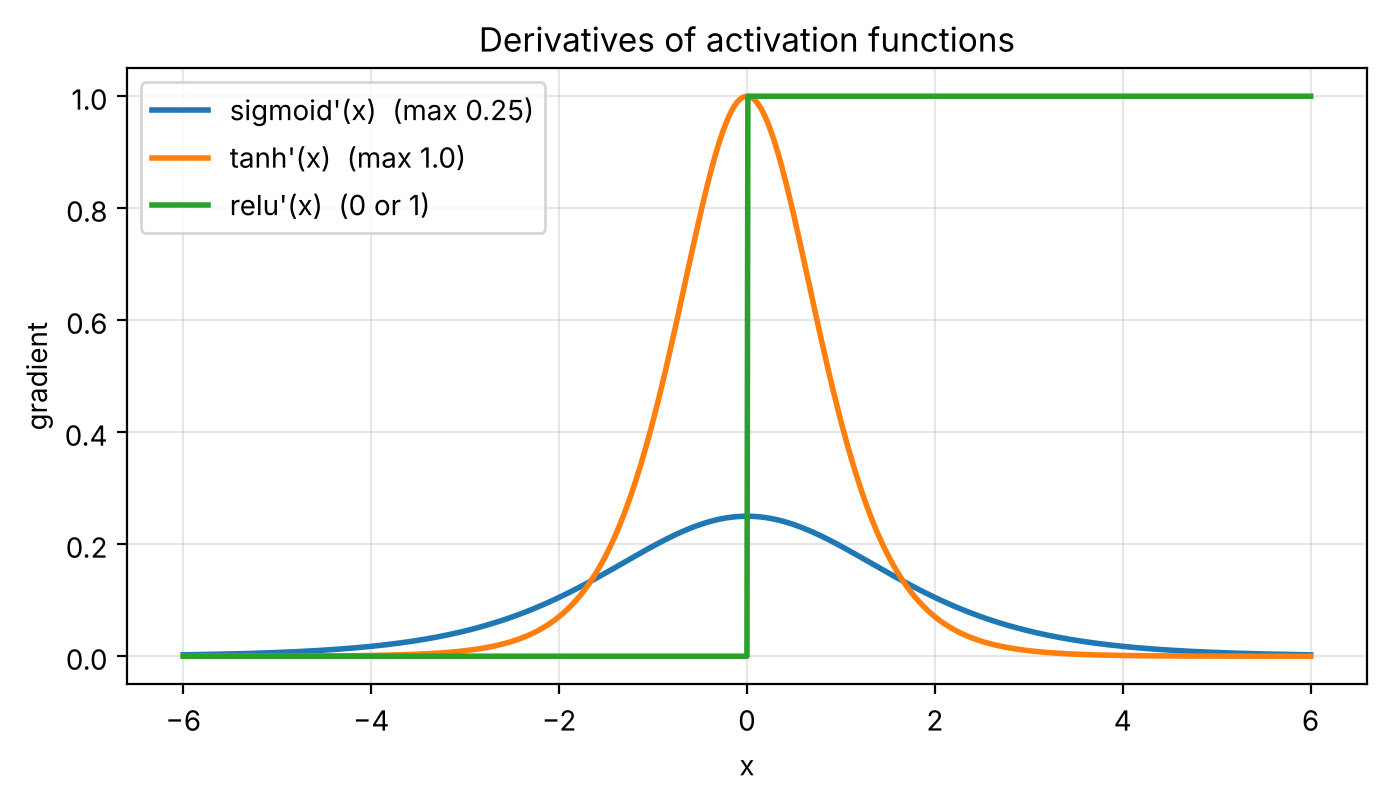

In [8]:
xg = np.linspace(-6, 6, 1201)                  # -6~6 구간을 0.01 간격으로 촘촘하게 (x=0 포함)

d_sigmoid = sigmoid(xg) * (1 - sigmoid(xg))    # sigmoid의 도함수 공식: σ(x)·(1-σ(x))
d_tanh = 1 - np.tanh(xg) ** 2                  # tanh의 도함수 공식: 1 - tanh²(x)
d_relu = (xg > 0).astype(float)                # ReLU의 도함수: 양수면 1, 음수면 0

print(f"Sigmoid 기울기의 최댓값: {d_sigmoid.max():.4f}  (x=0에서)")  # 0.25가 최대
print(f"Tanh    기울기의 최댓값: {d_tanh.max():.4f}")                # 1이 최대
print(f"ReLU    기울기 (x>0 구간): {d_relu[xg > 0].min():.1f} ~ {d_relu[xg > 0].max():.1f}")  # 항상 1

# 층이 깊어질 때: sigmoid 기울기의 '최댓값'(0.25)만 계속 곱해도 얼마나 작아지는지
for n_layers in [1, 5, 10]:                    # 층 수를 1, 5, 10으로 바꿔 가며
    print(f"  0.25를 {n_layers:>2}번 곱하면: {0.25 ** n_layers:.2e}")  # 지수 표기(e)로 출력
print("  → ReLU는 양수 구간 기울기가 1이라 여러 번 곱해도 1 그대로입니다.")

plt.figure(figsize=(8, 4))                                             # 새 그림
plt.plot(xg, d_sigmoid, label="sigmoid'(x)  (max 0.25)", linewidth=2)  # sigmoid 기울기 곡선
plt.plot(xg, d_tanh, label="tanh'(x)  (max 1.0)", linewidth=2)         # tanh 기울기 곡선
plt.plot(xg, d_relu, label="relu'(x)  (0 or 1)", linewidth=2)          # relu 기울기
plt.title('Derivatives of activation functions')                       # 제목
plt.xlabel('x'); plt.ylabel('gradient')                                # 축 이름
plt.legend(); plt.grid(True, alpha=0.3)                                # 범례·격자
plt.show()                                                             # 출력

### [필수] 과제 3-1: 활성화 함수 이해도 점검

아래 질문에 답하세요:

1. 은닉층에서 ReLU가 Sigmoid보다 많이 사용되는 이유는?
   - 답변: Sigmoid는 기울기(도함수)의 최댓값이 **0.25**밖에 안 돼서, 역전파 때 층마다 기울기가 곱해지면 앞쪽 층으로 갈수록 기울기가 0에 가까워지는 **기울기 소실(vanishing gradient)** 문제가 생깁니다(위 계산에서 최댓값 0.25만 10번 곱해도 9.54e-07). 반면 ReLU는 양수 구간의 기울기가 항상 **1**이라 깊은 층까지 기울기가 잘 전달되고, `max(0, x)`라는 단순한 계산이라 속도도 빠르기 때문에 은닉층의 기본 선택이 되었습니다.
   - 💡 비유: 기울기 전달은 '귓속말 전달 게임'과 비슷해요. Sigmoid는 한 사람 건널 때마다 목소리가 1/4 이하로 작아져 끝까지 전달이 안 되고, ReLU는 (양수일 때) 목소리 크기 그대로 전달됩니다. 단, 입력이 계속 음수면 기울기가 0이 되어 뉴런이 '죽는' Dying ReLU 문제가 있어서 Leaky ReLU 같은 변형도 씁니다.

2. 이진 분류 문제의 **출력층**에서 어떤 활성화 함수를 사용해야 하나요? 그 이유는?
   - 답변: **Sigmoid**를 사용합니다. 출력이 0~1 사이로 압축되므로 "양성(1) 클래스일 **확률**"로 해석할 수 있고, 보통 0.5를 기준으로 0/1을 결정하며, 이진 교차 엔트로피(BCE) 손실과 짝을 이뤄 학습합니다.
   - 참고: PyTorch에서는 마지막 층에 Sigmoid를 따로 두지 않고 `nn.BCEWithLogitsLoss`(내부에 Sigmoid가 포함된 손실 함수)를 쓰는 방식이 수치적으로 더 안정적이라 실무에서 자주 쓰입니다. 클래스가 3개 이상이면 Softmax를 씁니다(아래 Part 4).

---

## Part 4: [도전] Softmax 함수 구현

다중 클래스 분류에서 사용하는 Softmax 함수를 직접 구현해보세요.

In [9]:
# [도전 과제] Softmax 함수 구현
# 공식: softmax(x_i) = exp(x_i) / sum(exp(x_j))
# 구현 요령: 모든 값에서 최댓값을 빼고 exp를 계산 → 결과는 수학적으로 똑같지만 exp 값이 너무 커지는(overflow) 것을 막아 줌

def softmax(x):
    """
    Softmax 함수: 입력을 확률 분포로 변환
    - 모든 출력의 합이 1이 됨
    - 다중 클래스 분류의 출력층에서 사용
    """
    x = np.asarray(x, dtype=float)   # 리스트가 들어와도 계산할 수 있게 numpy 실수 배열로 변환
    shifted = x - np.max(x)          # 최댓값을 빼서 가장 큰 값이 0이 되게 이동 (exp(0)=1 → 안전)
    exp_x = np.exp(shifted)          # 각 값에 exp 적용 → 모두 양수가 됨 (큰 값일수록 더 크게 강조)
    return exp_x / np.sum(exp_x)     # 전체 합으로 나눠서 합이 1인 '확률'로 만들기

# 테스트
test_input = np.array([2.0, 1.0, 0.1])          # 예시 점수(로짓) 3개
result = softmax(test_input)                    # softmax 적용
print(f"입력: {test_input}")                     # 입력 출력
print(f"Softmax 출력: {result}")                 # 확률 출력
print(f"합계: {np.sum(result):.4f} (1이 되어야 함)")  # 합이 1인지 확인

# 추가 확인: 값이 매우 클 때 '최댓값 빼기'가 왜 필요한지
big = np.array([1000.0, 1001.0, 1002.0])        # exp(1000)은 컴퓨터가 표현할 수 없을 만큼 큰 수
with np.errstate(over='ignore', invalid='ignore'):  # 일부러 overflow를 내 보는 것이므로 경고는 숨김
    naive = np.exp(big) / np.sum(np.exp(big))   # 최댓값을 빼지 않은 '순진한' 구현
print(f"\n[큰 입력] 단순 구현: {naive}  ← inf/inf 라서 nan(숫자가 아님)")  # 계산 실패
print(f"[큰 입력] 안정 구현: {softmax(big)}  ← 정상 계산")                 # 우리 함수는 정상

입력: [2.  1.  0.1]
Softmax 출력: [0.65900114 0.24243297 0.09856589]
합계: 1.0000 (1이 되어야 함)

[큰 입력] 단순 구현: [nan nan nan]  ← inf/inf 라서 nan(숫자가 아님)
[큰 입력] 안정 구현: [0.09003057 0.24472847 0.66524096]  ← 정상 계산


---

## 1일차 학습 정리

오늘 배운 핵심 내용을 체크해보세요:

- [x] 퍼셉트론의 구조 (입력, 가중치, 편향, 활성화 함수) 이해
- [x] AND, OR, NAND 게이트를 퍼셉트론으로 구현 가능
- [x] XOR은 단일 퍼셉트론으로 불가능 -> 다층 퍼셉트론 필요
- [x] 활성화 함수의 역할: 비선형성 부여
- [x] ReLU vs Sigmoid의 차이점 이해

---

## 수고하셨습니다!

### 제출 전 체크리스트
- [x] 과제 1-1 (NAND 게이트) 완료
- [x] 과제 2-1 (퍼셉트론 이해) 답변 작성
- [x] 과제 3-1 (활성화 함수 이해) 답변 작성
- [x] [선택] 도전 과제 (Softmax 구현)

## 📌 핵심 정리

- **퍼셉트론** = `가중합(z = w₁x₁ + w₂x₂ + b)` → `활성화 함수`. 가중치는 입력의 중요도, 편향은 "얼마나 쉽게 1을 내보낼지"를 정하는 기준점입니다.
- **NAND**는 AND의 가중치·편향 부호를 뒤집어 만들 수 있습니다(z의 부호가 뒤집혀 출력이 반대가 됨).
- 단일 퍼셉트론은 **직선 하나**로만 나눌 수 있어서 XOR이 불가능합니다(9,261가지 조합 실험에서 0개). 퍼셉트론을 **층으로 쌓으면(MLP)** 여러 직선을 조합해 비선형 문제를 풉니다.
- **활성화 함수**가 비선형성을 줘야 층을 쌓는 의미가 생깁니다. 은닉층은 기울기가 잘 전달되는 **ReLU**, 이진 분류 출력층은 **Sigmoid**, 다중 분류 출력층은 **Softmax**가 기본입니다.
- Softmax는 `exp`가 폭발하지 않도록 **최댓값을 빼고 계산**하는 것이 정석입니다.
- 다음 단계: 2일차에는 이 퍼셉트론들을 PyTorch로 여러 층 쌓아서(MLP) 실제 당뇨병 데이터를 학습시킵니다.